# Sensitivity analysis with distribution factors

How does the flow on a line change if a generator feeds in 10 MW more? Which lines take over the flow if a line trips? And how much can a phase shifting transformer move?

Questions like these can of course be answered with one power flow per scenario. If there are many scenarios, e.g. all N-1 cases or all time steps of a year, it pays off to calculate the **linear sensitivities** of the branch flows once and then get each scenario with a simple multiplication. These sensitivities are called **distribution factors**, and the `pandapower.sensitivity` module provides three of them:

| Factor | Question it answers | Function |
|---|---|---|
| **PTDF** (power transfer distribution factor) | How does the flow on a branch change if 1 MW more is injected at a bus? | `run_ptdf` |
| **LODF** (line outage distribution factor) | How much of a branch's flow moves onto the other branches if it is switched off? | `run_lodf` |
| **PSDF** (phase shift distribution factor) | How do the branch flows change if the phase shift of a transformer is increased by 1 degree? | `run_psdf` |

All three are based on the **DC power flow**. They are exact for `rundcpp`, and a linear approximation of the AC power flow, since losses, reactive power and voltage magnitudes are neglected.

In [1]:
import copy
import time

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from pandapower.control import ConstControl
from pandapower.create import create_sgen
from pandapower.networks import case14, case30
from pandapower.run import rundcpp
from pandapower.sensitivity.lodf import run_lodf, run_lodf_dc_n1
from pandapower.sensitivity.psdf import run_psdf
from pandapower.sensitivity.ptdf import run_ptdf, run_ptdf_dc_profile
from pandapower.timeseries import DFData, OutputWriter, run_timeseries

## The example grid

For most of this tutorial we use the IEEE 30 bus test case. It has 30 buses, 41 lines and one external grid as slack. We run a DC power flow to get the flows we will compare against later:

In [2]:
net = case30()
rundcpp(net)
p_line_base = net.res_line.p_from_mw.copy()
net.res_line[["p_from_mw", "p_to_mw"]].head()

,p_from_mw,p_to_mw
0,9.169470,-9.169470
1,14.360530,-14.360530
2,15.627963,-15.627963
3,11.960530,-11.960530
4,13.327709,-13.327709


## Power Transfer Distribution Factors (PTDF)

The PTDF tells us how much the flow on a branch changes if 1 MW more is injected at a bus, while the slack takes up the difference. `run_ptdf` returns a dictionary with one DataFrame per branch type. The rows are the branches and the columns the buses where the additional megawatt is injected:

In [3]:
ptdf = run_ptdf(net)
ptdf["line"].round(2)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
0,0.0,-0.84,-0.51,-0.62,-0.75,-0.67,-0.70,-0.67,-0.66,-0.66,...,-0.65,-0.65,-0.65,-0.65,-0.66,-0.66,-0.66,-0.67,-0.66,-0.66
1,0.0,-0.16,-0.49,-0.38,-0.25,-0.33,-0.30,-0.33,-0.34,-0.34,...,-0.35,-0.35,-0.35,-0.35,-0.34,-0.34,-0.34,-0.33,-0.34,-0.34
2,0.0,0.08,-0.25,-0.30,-0.07,-0.21,-0.15,-0.21,-0.23,-0.24,...,-0.24,-0.24,-0.25,-0.24,-0.23,-0.23,-0.22,-0.21,-0.22,-0.22
3,0.0,-0.16,0.51,-0.38,-0.25,-0.33,-0.30,-0.33,-0.34,-0.34,...,-0.35,-0.35,-0.35,-0.35,-0.34,-0.34,-0.34,-0.33,-0.34,-0.34
4,0.0,0.03,-0.08,-0.10,-0.56,-0.14,-0.31,-0.14,-0.13,-0.13,...,-0.13,-0.13,-0.12,-0.13,-0.13,-0.13,-0.14,-0.14,-0.14,-0.14
5,0.0,0.06,-0.18,-0.22,-0.13,-0.31,-0.24,-0.31,-0.30,-0.29,...,-0.29,-0.29,-0.27,-0.29,-0.30,-0.30,-0.30,-0.31,-0.30,-0.30
6,0.0,-0.08,0.25,0.30,-0.29,-0.51,-0.43,-0.51,-0.38,-0.30,...,-0.30,-0.30,-0.17,-0.27,-0.35,-0.35,-0.40,-0.50,-0.40,-0.40
7,0.0,0.03,-0.08,-0.10,0.44,-0.14,-0.31,-0.14,-0.13,-0.13,...,-0.13,-0.13,-0.12,-0.13,-0.13,-0.13,-0.14,-0.14,-0.14,-0.14
8,0.0,-0.03,0.08,0.10,-0.44,0.14,-0.69,0.14,0.13,0.13,...,0.13,0.13,0.12,0.13,0.13,0.13,0.14,0.14,0.14,0.14
9,0.0,0.00,-0.00,-0.00,0.00,0.00,0.00,-0.86,-0.01,-0.02,...,-0.02,-0.03,-0.03,-0.04,-0.10,-0.10,-0.13,-0.19,-0.13,-0.13


The column of bus 0 only contains zeros: bus 0 is the slack, so injecting power there does not change any flow. A heat map gives a good overview of the whole matrix. Dark colours mark the buses that have a strong influence on a line:

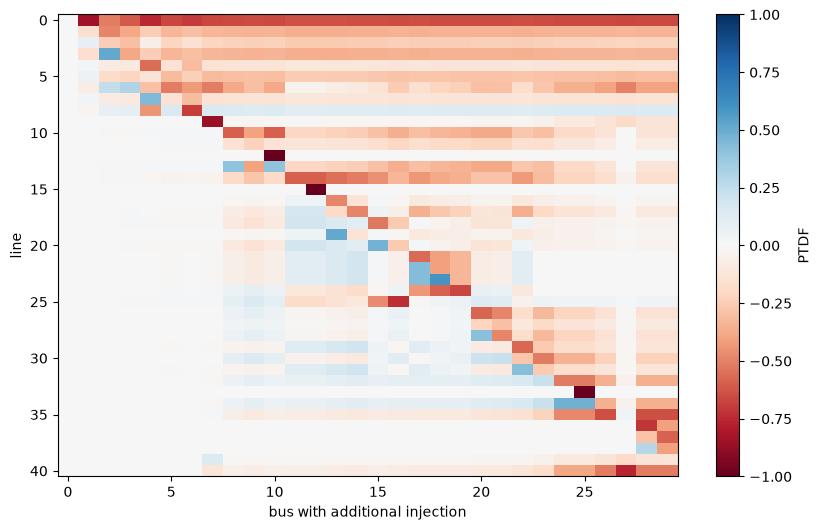

In [4]:
fig, ax = plt.subplots(figsize=(10, 6))
image = ax.imshow(ptdf["line"].to_numpy(), cmap="RdBu", vmin=-1, vmax=1, aspect="auto")
ax.set_xlabel("bus with additional injection")
ax.set_ylabel("line")
fig.colorbar(image, ax=ax, label="PTDF")
plt.show()

### Using the PTDF

Let's say a generator at bus 9 feeds in 10 MW more. With the PTDF, the new line flows are simply the old flows plus 10 times the column of bus 9. To see that this works, we also add a static generator with 10 MW at bus 9 and run the DC power flow again:

In [5]:
net_10mw = copy.deepcopy(net)
create_sgen(net_10mw, bus=9, p_mw=10)
rundcpp(net_10mw)

pd.DataFrame(
    {
        "before": p_line_base,
        "after (DC power flow)": net_10mw.res_line.p_from_mw,
        "after (PTDF)": p_line_base + 10 * ptdf["line"][9],
    }
).head(10).round(3)

,before,after (DC power flow),after (PTDF)
0,9.169,2.618,2.618
1,14.361,10.912,10.912
2,15.628,13.275,13.275
3,11.961,8.512,8.512
4,13.328,12.024,12.024
5,19.484,16.588,16.588
6,21.258,18.225,18.225
7,13.328,12.024,12.024
8,9.472,10.776,10.776
9,24.746,24.554,24.554


Both ways give the same flows. The difference is that the PTDF answers the question for every bus at once, while the power flow has to be repeated for every new injection.

### Calculating only what you need

In large grids, the full PTDF can get big. There are three ways to reduce the effort:

* `source_bus`: only the columns of these buses are returned.
* `branch_dict`: only the rows of these branches are calculated, e.g. `{"line": [0, 1, 2], "trafo": [0]}`.
* `perturb=True`: instead of the matrix calculation, one DC power flow is run per source bus. This is faster if only a few buses are of interest in a large grid.

The perturb method gives the same values as the matrix calculation:

In [6]:
ptdf_matrix = run_ptdf(net, source_bus=np.array([9, 10]), branch_dict={"line": [0, 1, 2, 3, 4]})
ptdf_perturb = run_ptdf(net, source_bus=np.array([9, 10]), perturb=True)

pd.concat(
    {"matrix": ptdf_matrix["line"], "perturb": ptdf_perturb["line"].loc[ptdf_matrix["line"].index]}, axis=1
).round(4)

matrix         perturb        
       9       10      9       10
0 -0.6552 -0.6598 -0.6552 -0.6598
1 -0.3448 -0.3402 -0.3448 -0.3402
2 -0.2353 -0.2274 -0.2353 -0.2274
3 -0.3448 -0.3402 -0.3448 -0.3402
4 -0.1303 -0.1342 -0.1303 -0.1342

## DC time series with the PTDF

The PTDF really shines when many injection scenarios have to be calculated, for example the time steps of a load profile. `run_ptdf_dc_profile` calculates the branch flows of all time steps with a single matrix product instead of one power flow per time step.

The profiles are given per element type as DataFrames, with the time steps as index and the element indices as columns. Elements without a profile keep their value from the net. Here, all loads follow a simple daily curve between 60 % and 120 % of their nominal value:

In [7]:
def get_load_profiles(n_steps):
    scaling = 0.9 + 0.3 * np.sin(np.linspace(0, 2 * np.pi, n_steps))
    return {
        ("load", "p_mw"): pd.DataFrame(
            np.outer(scaling, net.load.p_mw.to_numpy()), index=np.arange(n_steps), columns=net.load.index
        )
    }


profiles = get_load_profiles(96)
res_profile = run_ptdf_dc_profile(net, profiles)
res_profile[("res_line", "p_from_mw")].head().round(2)

,0,1,2,3,4,5,6,7,8,9,...,31,32,33,34,35,36,37,38,39,40
0,-3.66,8.27,11.97,6.11,10.84,14.97,16.48,10.84,9.68,21.76,...,7.43,-3.84,3.15,-6.99,-8.22,5.44,6.26,3.28,-5.24,-2.98
1,-1.12,9.48,12.70,7.27,11.33,15.86,17.43,11.33,9.64,22.35,...,7.44,-3.90,3.22,-7.12,-7.83,5.56,6.40,3.35,-5.25,-2.59
2,1.42,10.68,13.42,8.42,11.82,16.76,18.37,11.82,9.60,22.94,...,7.45,-3.96,3.29,-7.25,-7.45,5.68,6.54,3.42,-5.25,-2.20
3,3.93,11.87,14.13,9.57,12.31,17.64,19.31,12.31,9.56,23.52,...,7.46,-4.02,3.36,-7.37,-7.07,5.79,6.67,3.49,-5.25,-1.82
4,6.40,13.05,14.84,10.70,12.79,18.51,20.23,12.79,9.52,24.10,...,7.46,-4.07,3.42,-7.50,-6.69,5.91,6.81,3.56,-5.25,-1.44


`run_ptdf_dc_profile` only calculates branch flows. If you need other results, such as the voltage angles, or want to use controllers, the time series module with `run_timeseries(net, run=rundcpp)` runs one DC power flow per time step. Let's compare the two for the first lines:

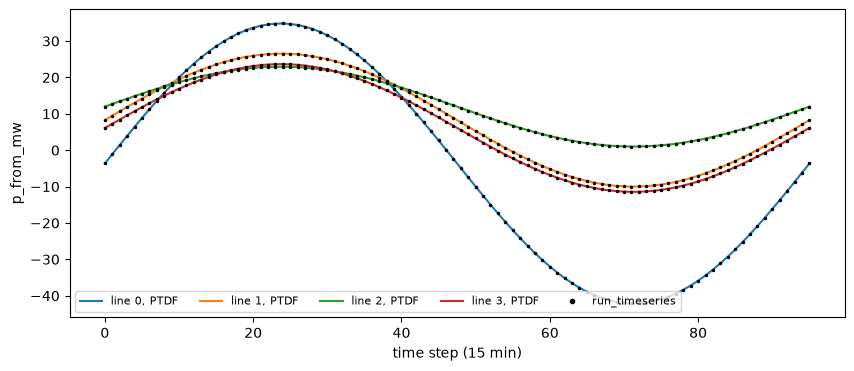

In [8]:
def run_dc_timeseries(net, profiles):
    net = copy.deepcopy(net)
    load_profile = profiles[("load", "p_mw")]
    ConstControl(
        net,
        element="load",
        variable="p_mw",
        element_index=load_profile.columns,
        data_source=DFData(load_profile),
        profile_name=load_profile.columns,
    )
    ow = OutputWriter(net, time_steps=load_profile.index, output_path=None, log_variables=[("res_line", "p_from_mw")])
    run_timeseries(net, time_steps=load_profile.index, run=rundcpp, verbose=False)
    return ow.output["res_line.p_from_mw"]


res_timeseries = run_dc_timeseries(net, profiles)

fig, ax = plt.subplots(figsize=(10, 4))
for line in [0, 1, 2, 3]:
    ax.plot(res_profile[("res_line", "p_from_mw")][line], label=f"line {line}, PTDF")
    ax.plot(res_timeseries[line], "k.", markersize=3)
ax.plot([], [], "k.", label="run_timeseries")
ax.set_xlabel("time step (15 min)")
ax.set_ylabel("p_from_mw")
ax.legend(ncol=5, fontsize=8, loc="lower left")
plt.show()

The dots of the time series simulation lie exactly on the PTDF curves.

`run_ptdf_dc_profile` calculates the PTDF in every call. If several profiles are calculated for the same grid, we can calculate the PTDF once and pass it with `ptdf=`. Just keep in mind that the PTDF is only valid for the grid state it was calculated for: after switching lines or changing the slacks, it has to be calculated again.

How much time does that save? We compare both ways for a day in hourly, 15-minute and 5-minute resolution:

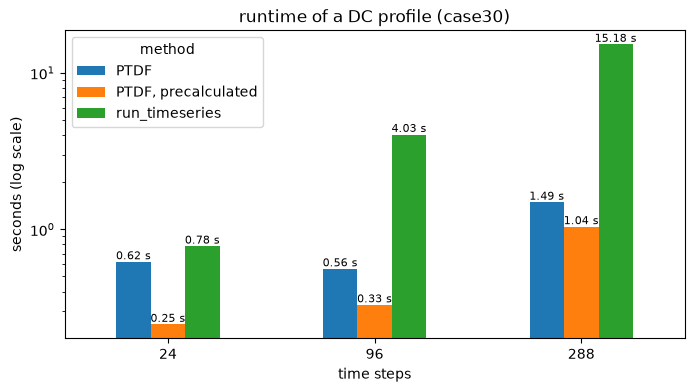

In [18]:
timings = []
for n_steps in (24, 96, 288):
    profiles_n = get_load_profiles(n_steps)

    start = time.perf_counter()
    run_ptdf_dc_profile(net, profiles_n)
    timings.append({"time steps": n_steps, "method": "PTDF", "seconds": time.perf_counter() - start})

    start = time.perf_counter()
    run_ptdf_dc_profile(net, profiles_n, ptdf=ptdf)
    timings.append({"time steps": n_steps, "method": "PTDF, precalculated", "seconds": time.perf_counter() - start})

    start = time.perf_counter()
    run_dc_timeseries(net, profiles_n)
    timings.append({"time steps": n_steps, "method": "run_timeseries", "seconds": time.perf_counter() - start})

timings = pd.DataFrame(timings).pivot(index="time steps", columns="method", values="seconds")
ax = timings.plot.bar(figsize=(8, 4), rot=0, logy=True, title="runtime of a DC profile (case30)")
ax.set_ylabel("seconds (log scale)")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f s", fontsize=8)
plt.show()

The time series simulation needs one power flow per time step, so its runtime grows with the number of time steps. The PTDF runtime hardly changes, since most of the time is spent on setting up the PTDF itself. In larger grids, where a single power flow takes longer, the difference grows even further.

## Line Outage Distribution Factors (LODF)

The LODF tells us which share of a branch's flow moves onto another branch if the branch is switched off. With the LODF, the flow on line $l$ after the outage of line $k$ is

$$P_l^{N-1} = P_l^{0} + LODF_{l,k} \cdot P_k^{0}$$

Despite the name, the LODF can also be calculated for the outage of transformers and impedances. The result is a dictionary with one DataFrame per combination of branch type and outage branch type. The rows are the branches and the columns the switched off branches:

In [10]:
lodf = run_lodf(net, outage_branch_type="line", outage_branch_ix=[0, 5, 10], distributed_slack=False)
lodf[("line", "line")].head(12).round(3)

,0,5,10
0,-1.000,-0.271,-0.023
1,1.000,0.271,0.023
2,-0.488,0.463,0.039
3,1.000,0.271,0.023
4,-0.159,0.266,-0.019
5,-0.353,-1.000,-0.043
6,0.482,0.691,-0.357
7,-0.159,0.266,-0.019
8,0.159,-0.266,0.019
9,-0.001,-0.002,0.035


The diagonal entries are -1: a line that is switched off loses its entire flow. Note that we pass `distributed_slack=False`: the LODF does not depend on the slack, and the matrix calculation would otherwise log a warning.

Let's check what happens if line 5 is switched off, again by comparing with a DC power flow:

In [11]:
net_n1 = copy.deepcopy(net)
net_n1.line.at[5, "in_service"] = False
rundcpp(net_n1)

pd.DataFrame(
    {
        "before": p_line_base,
        "after outage (DC power flow)": net_n1.res_line.p_from_mw,
        "after outage (LODF)": p_line_base + lodf[("line", "line")][5] * p_line_base[5],
    }
).head(12).round(3)

,before,after outage (DC power flow),after outage (LODF)
0,9.169,3.883,3.883
1,14.361,19.647,19.647
2,15.628,24.646,24.646
3,11.961,17.247,17.247
4,13.328,18.507,18.507
5,19.484,0.000,0.000
6,21.258,34.721,34.721
7,13.328,18.507,18.507
8,9.472,4.293,4.293
9,24.746,24.713,24.713


Line 5 itself carries no flow anymore after the outage, and all other lines match the DC power flow.

### Bridges

Some lines cannot be switched off without splitting the grid, e.g. the only line to a bus. For these **bridges**, the LODF has no meaning, and their columns are `NaN`:

In [12]:
lodf_all = run_lodf(net, outage_branch_type="line", distributed_slack=False)[("line", "line")]
bridges = lodf_all.columns[lodf_all.isna().all()]
net.line.loc[bridges, ["from_bus", "to_bus"]]

,from_bus,to_bus
12,8,10
15,11,12
33,24,25


### N-1 flows

`run_lodf_dc_n1` applies the LODF to the base case and directly returns the flows after each outage, one column per switched off line. That makes a quick N-1 screening easy: for each line, we look for the outage that loads it the most:

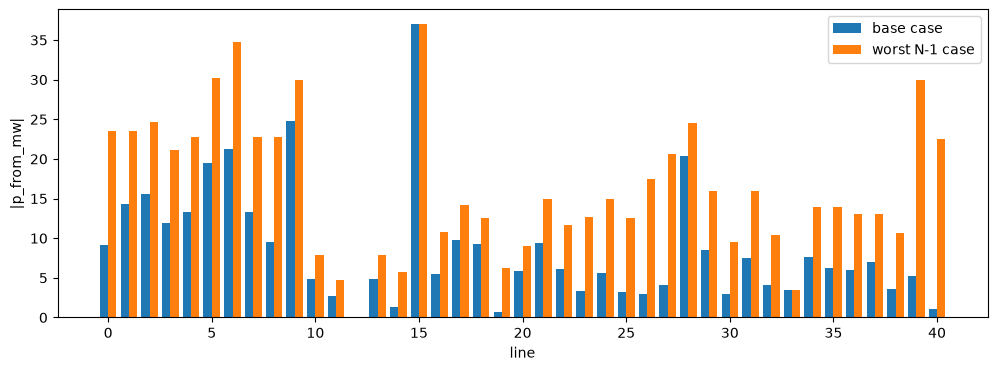

In [13]:
p_n1 = run_lodf_dc_n1(net, outage_branch_type="line", distributed_slack=False)[("res_line", "p_from_mw")]
worst_n1 = p_n1.abs().max(axis=1)

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(net.line.index - 0.2, p_line_base.abs(), width=0.4, label="base case")
ax.bar(net.line.index + 0.2, worst_n1, width=0.4, label="worst N-1 case")
ax.set_xlabel("line")
ax.set_ylabel("|p_from_mw|")
ax.legend()
plt.show()

The outages of the bridges 12, 15 and 33 are not part of the screening, their columns are `NaN` as explained above.

For the details of each N-1 case, e.g. which outage causes the highest flow on line 0, the columns of `p_n1` can be looked at directly:

In [14]:
print(f"line 0 is loaded the most by the outage of line {p_n1.loc[0].abs().idxmax()}")
p_n1.loc[[0, 1, 2]].round(1)

line 0 is loaded the most by the outage of line 1


,0,1,2,3,4,5,6,7,8,9,...,31,32,33,34,35,36,37,38,39,40
0,0.0,23.5,3.6,21.1,6.4,3.9,14.9,6.4,11.1,9.1,...,9.3,9.1,NaN,9.0,9.3,9.2,9.2,9.2,9.2,9.2
1,23.5,0.0,20.0,2.4,17.1,19.6,8.6,17.1,12.4,14.4,...,14.2,14.4,NaN,14.5,14.2,14.4,14.4,14.4,14.4,14.4
2,11.2,22.6,0.0,21.5,20.3,24.6,5.8,20.3,12.3,15.7,...,15.4,15.8,NaN,15.9,15.4,15.6,15.6,15.6,15.6,15.6


## Phase Shift Distribution Factors (PSDF)

Phase shifting transformers control the flow of active power by shifting the voltage angle. The PSDF tells us how much the flows change, in MW, if the phase shift of a transformer is increased by 1 degree.

The IEEE 30 bus case has no transformers, so we use the IEEE 14 bus case with five transformers here. By default, `run_psdf` calculates the PSDF for all transformers:

In [15]:
net14 = case14()
rundcpp(net14)
p_line_base14 = net14.res_line.p_from_mw.copy()

psdf = run_psdf(net14, distributed_slack=False)
psdf[("line", "trafo")].round(3)

,0,1,2,3,4
0,-0.087,-0.051,0.138,-0.0,-0.087
1,0.087,0.051,-0.138,0.0,0.087
2,-0.074,-0.043,0.117,-0.0,-0.074
3,-0.155,-0.090,0.245,0.0,-0.155
4,0.141,0.082,-0.224,0.0,0.141
5,-0.074,-0.043,0.117,0.0,-0.074
6,1.231,0.718,-1.949,0.0,1.231
7,0.879,0.513,-1.391,0.0,0.879
8,0.129,0.075,-0.204,0.0,0.129
9,0.451,0.263,-0.715,0.0,0.451


The column of transformer 3 only contains zeros. This transformer connects bus 7, which only has a generator, so there is no parallel path for a phase shift to push the flow around.

The PSDF follows the sign of the transformer parameter `shift_degree`: a positive value means that the flow increases if `shift_degree` increases. Let's increase the phase shift of transformer 0 by 5 degrees:

In [16]:
net14_shift = copy.deepcopy(net14)
net14_shift.trafo.at[0, "shift_degree"] += 5
rundcpp(net14_shift)

pd.DataFrame(
    {
        "before": p_line_base14,
        "after shift (DC power flow)": net14_shift.res_line.p_from_mw,
        "after shift (PSDF)": p_line_base14 + 5 * psdf[("line", "trafo")][0],
    }
).round(3)

,before,after shift (DC power flow),after shift (PSDF)
0,147.839,147.403,147.403
1,71.161,71.597,71.597
2,70.015,69.645,69.645
3,55.152,54.379,54.379
4,40.972,41.679,41.679
5,-24.185,-24.555,-24.555
6,-61.746,-55.593,-55.593
7,6.728,11.122,11.122
8,7.607,8.253,8.253
9,17.251,19.508,19.508


A few things to keep in mind with phase shifting tap changers:

* For an ideal phase shifter (`tap_changer_type="Ideal"`) on the high voltage side, a tap step changes the angle by `tap_step_degree`, with the same sign as `shift_degree`. On the low voltage side, pandapower applies the tap angle with the opposite sign.
* For non-ideal phase shifters (`"Symmetrical"`, `"Ratio"`, `"Tabular"`), the angle per tap step follows from the tap changer model, and a tap step also changes the voltage ratio. The PSDF times the angle change is then a good approximation, but not exact.

### Where would a phase shifter help the most?

With `phase_shift_branch_type="line"`, the PSDF tells us what a phase shifter in series with a line would do. Lines have no phase shift parameter in pandapower, but this is a quick way to find promising locations for a new phase shifter. Here we sum up the absolute flow changes on all lines:

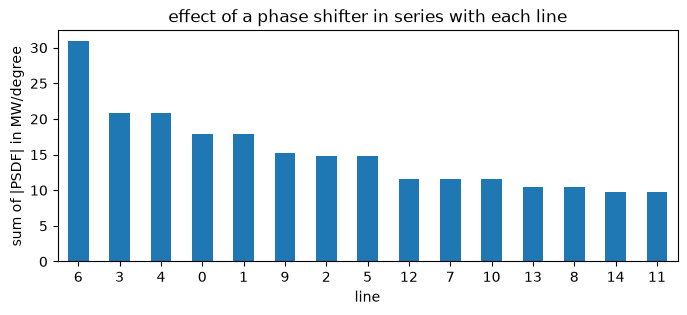

In [17]:
psdf_lines = run_psdf(net14, phase_shift_branch_type="line", distributed_slack=False)[("line", "line")]
effect = psdf_lines.abs().sum().sort_values(ascending=False)

ax = effect.plot.bar(figsize=(8, 3), rot=0, title="effect of a phase shifter in series with each line")
ax.set_xlabel("line")
ax.set_ylabel("sum of |PSDF| in MW/degree")
plt.show()

## Summary

* The **PTDF** describes how the branch flows react to injections at the buses. With `run_ptdf_dc_profile`, it calculates the flows of whole profiles at once.
* The **LODF** describes how the flow of a switched off branch is redistributed. `run_lodf_dc_n1` uses it for a fast N-1 screening.
* The **PSDF** describes how phase shifts change the branch flows, and helps to find good locations for phase shifters.

All distribution factors are valid for the grid state they were calculated for, and they are based on the DC power flow. For exact AC results of the critical cases, an AC power flow or a contingency analysis with `run_contingency` is the natural next step.

More details, e.g. on the slack handling and the limitations, can be found in the documentation of the sensitivity package.